# Crop Yield Prediction - Multivariate Regression

**Mission:** My goal is to use machine learning to predict crop yields in Rwanda. This can help agricultural officers and district planners make better farming decisions using data.

**Use Case:** The user enters details such as the crop, country, season, farming system, planting and harvesting months, years and land area. My model then predicts the expected crop yield in tonnes per hectare. This can help compare crop performance and plan farming activities.

**Dataset:** I am using HarvestStat dataset (FEWS NET / FAO) which contains crop statistics from 33 African countries. Rwanda is my main focus but I will use  the full dataset to give my model more data to learn from.

**Target:** `yield` The is the value my model will predict. It represents crop production in tonnes per hectare.

In [1]:
# 1. Imports
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.utils import shuffle

sns.set_style("whitegrid")

# 2. Loading the data  

In [2]:
DATA_PATH = "hvstat_africa_data_v1.0.csv"

df = pd.read_csv(DATA_PATH)

print("Raw shape:", df.shape)
df.head()

df.info()

Raw shape: (203125, 16)
<class 'pandas.DataFrame'>
RangeIndex: 203125 entries, 0 to 203124
Data columns (total 16 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   fnid                    203125 non-null  str    
 1   country                 203125 non-null  str    
 2   country_code            203125 non-null  str    
 3   admin_1                 203125 non-null  str    
 4   admin_2                 203125 non-null  str    
 5   product                 203125 non-null  str    
 6   season_name             203125 non-null  str    
 7   planting_year           203125 non-null  int64  
 8   planting_month          203125 non-null  int64  
 9   harvest_year            203125 non-null  int64  
 10  harvest_month           203125 non-null  int64  
 11  crop_production_system  203125 non-null  str    
 12  qc_flag                 203125 non-null  int64  
 13  area                    190428 non-null  float64
 14  product

# 3. Cleaning the data

Decisions made and why:
- Remove rows with missing yield or area because they are important for training the model.
- Remove rows where yield  or area is zero or negative because they are not valid values.
- Remove yields above 50 t/ha because they are likely data errors or unusual values that could affect model performance.
- Keep records from 1995 onwards because there's limited data available for ealier years.



In [3]:
print("Rows before cleaning:", len(df))

# 1. missing values
df = df.dropna(subset=["yield", "area"])
print("After dropping missing yield/area:", len(df))

# 2. zero or negative values
df = df[(df["yield"] > 0) & (df["area"] > 0)]
print("After dropping zero/negative:", len(df))

# 3. extreme yields
df = df[(df["yield"] <= 50)]
print("After removing yield > 50:", len(df))

# 4. old years
df = df[df["harvest_year"] >= 1995].copy()
print("After keeping 1995 onwards:", len(df))

# 5. impossible areas
df = df[df["area"] <= 5000000]
print("After removing area > 5,000,000:", len(df))

Rows before cleaning: 203125
After dropping missing yield/area: 185430
After dropping zero/negative: 185430
After removing yield > 50: 184990
After keeping 1995 onwards: 160005
After removing area > 5,000,000: 159999


# Group rare categories

`season_name` has about 30 values while `crop_production_system` has about 27. Some categories have very few records. I keep the most common categories and group the rest as `"Other"`. This reduces the encoded data and makes the app easier to use.

In [4]:
def keep_top(column, n):
    # keep the n most common values, replace everything with "Other"
    top_values = column.value_counts().nlargest(n).index
    return column.where(column.isin(top_values), "Other")

top_seasons= df["season_name"].value_counts().nlargest(9).index
rwanda_seasons = df.loc[df["country"] == "Rwanda", "season_name"].unique()
keep_seasons = set(top_seasons) | set(rwanda_seasons)
df["season_name"] = df["season_name"].where(df["season_name"].isin(keep_seasons), "Other")
df["crop_production_system"] = keep_top(df["crop_production_system"], 5)

print(df["season_name"].value_counts())
print()
print(df["crop_production_system"].value_counts())

season_name
Main        68354
Annual      41588
Meher       13570
Other        9623
Wet          6932
Dry          6589
Summer       2644
Deyr         2501
Gu           2476
Long         1986
Season B     1678
Season A     1636
Season C      422
Name: count, dtype: int64

crop_production_system
All (PS)           69708
none               51455
Rainfed (PS)       20846
irrigated           8363
Other               7789
Commercial (PS)     1838
Name: count, dtype: int64


### Feature engineering: which columns we keep and drop

**`Kept (8 features):`**
`country`, `product`, `season_name`, `crop_production_system`, `planting_month`, `harvest_month`, `harvest_year`, `area`

**Dropped:**
- `production`: It is calculated using `yield × area` so it would cause data leakage. 
- `country_code`: It is duplicate of country.
- `admin_1`, `admin_2`, `fnid`: The contain to many unique values or are just identifiers.
- `planting_year`, `qc_flag`: not useful as inputs.

In [5]:
features = ["country", "product", "season_name", "crop_production_system",
            "planting_month", "harvest_month", "harvest_year", "area"]
target = "yield"

df = df[features + [target]].reset_index(drop=True)
print("Final shape:", df.shape)
print(df["country"].unique())
print("Rwanda rows:", (df["country"] == "Rwanda").sum())
df.head()

Final shape: (159999, 9)
<StringArray>
[                      'Angola',                 'Burkina Faso',
                      'Burundi',                        'Benin',
                          'DRC',     'Central African Republic',
                     'Cameroon',                     'Ethiopia',
                        'Ghana',                        'Kenya',
                      'Liberia',                      'Lesotho',
                   'Madagascar',                         'Mali',
                   'Mauritania',                       'Malawi',
                   'Mozambique',                        'Niger',
                      'Nigeria',                       'Rwanda',
                        'Sudan',                      'Senegal',
                      'Somalia',                  'South Sudan',
                         'Chad',                         'Togo',
 'Tanzania, United Republic of',                       'Uganda',
                 'South Africa',                   

,country,product,season_name,crop_production_system,planting_month,harvest_month,harvest_year,area,yield
0,Angola,Banana,Main,All (PS),10,4,2008,1364.0,14.360704
1,Angola,Banana,Main,All (PS),10,4,2009,1364.0,15.000733
2,Angola,Banana,Main,All (PS),10,4,2015,8706.0,25.504709
3,Angola,Banana,Main,All (PS),10,4,2016,8706.0,25.504709
4,Angola,Banana,Main,All (PS),10,4,2017,9549.7,24.499932


## 4. Visualizations 

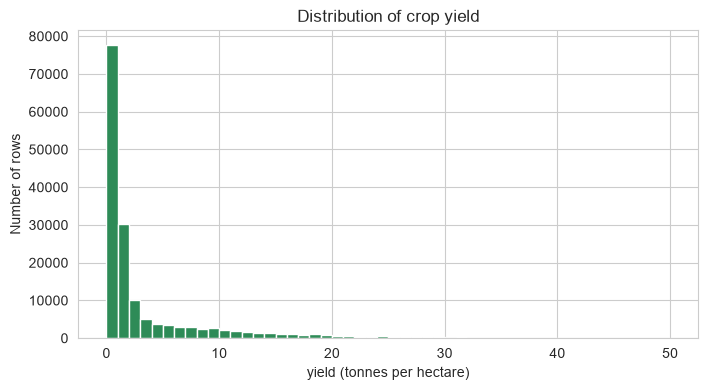

In [6]:
# Plot 1: Distribution of the target
plt.figure(figsize=(8,4))
plt.hist(df["yield"], bins=50, color="seagreen", edgecolor="white")
plt.xlabel("yield (tonnes per hectare)")
plt.ylabel("Number of rows")
plt.title("Distribution of crop yield")
plt.show()

**What it shows / what I decided:**

Most crop yields are around 1 tonne per hectare, with a few much higher values. The distribution has a long tail to the right. I removed yields above 50 to reduce the effect of extreme values on the model's MSE.

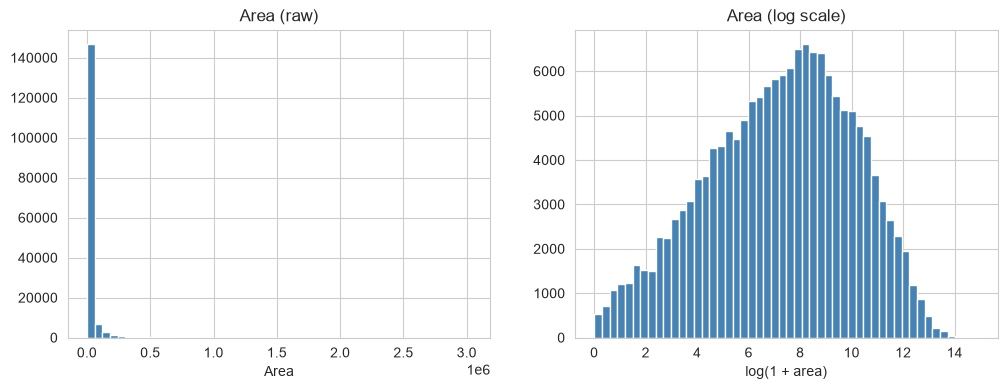

In [7]:
# Plot 2: area before and after a log transform
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["area"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("Area (raw)")
axes[0].set_xlabel("Area")

axes[1].hist(np.log1p(df["area"]), bins=50, color="steelblue", edgecolor="white")
axes[1].set_title("Area (log scale)")
axes[1].set_xlabel("log(1 + area)")

plt.show()

**What it shows / what I decided:**

The raw area has a lot of small values and a few very large ones. After applying a log transform, the distribution becomes more balanced. I decided to use log1p on area before scaling it.

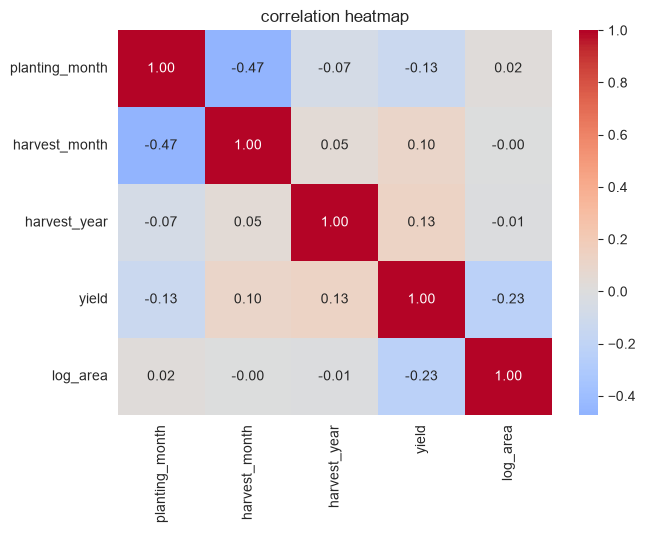

In [8]:
# Plot 3: correlation heatmap of the numeric columns
numeric_df = df[["planting_month", "harvest_month", "harvest_year", "area", "yield"]].copy()
numeric_df["log_area"] = np.log1p(numeric_df["area"])
numeric_df = numeric_df.drop(columns="area")

plt.figure(figsize=(7, 5))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("correlation heatmap")
plt.show()

**What it shows / what I decided:**

The numeric features have weak correlations with yield, meaning they don't strongly affect crop yield on their own. I expect categorical features like crop and country to provide more useful information. This is why I think tree-based models may perform better than linear models.

## 5. Train / test split

I split **by year** instead of randomly. I use harvests up to 2015 for training and those after 2015 for testing. This helps me check how well my model predicts future crop yields using past data.

In [9]:
train_df = df[df["harvest_year"] <= 2015]
test_df = df[df["harvest_year"] > 2015]

X_train = train_df[features]
y_train = train_df[target]
X_test = test_df[features]
y_test = test_df[target]

print("Train rows:", len(X_train))
print("Test rows:", len(X_test))
print("Test  share: {:.1%}".format(len(X_test) / len(df)))

Train rows: 124000
Test rows: 35999
Test  share: 22.5%


## 6. Converting categories to numbers and standardizing

- I use `OneHotEncoder` to convert categorical columns into numbers.
- I use `StandardScaler` to standardize numeric columns.
- I apply a log transform to `area` before standardizing it.

I fit the `ColumnTransformer` on the **training set only** and then use it to transform the test set. This helps prevent data leakage.


In [10]:
cat_cols = ["country", "product", "season_name", "crop_production_system"]
num_cols = ["planting_month", "harvest_month", "harvest_year"]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("num", StandardScaler(), num_cols),
    ("area", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), ["area"]),
])

# fit on train ONLY
X_train_s = preprocessor.fit_transform(X_train)
# the test set only gets transformed, never fitted
X_test_s = preprocessor.transform(X_test)

print("Train shape after preprocessor:", X_train_s.shape)
print("Test shape after preprocessing:", X_test_s.shape)

Train shape after preprocessor: (124000, 145)
Test shape after preprocessing: (35999, 145)


## 7. Model 1: SGDRegressor (Linear regression by gradient descent)

Scikit-learn does not automatically track the loss after each epoch, so I use `partial_fit` in a loop to train the model and record the train and test MSE after every epoch.

I also test different **learning rates** (eta0), **regularization strengths** (alpha), and **numbers of epochs** to find the best model settings.

In [11]:
def train_sgd(eta0, alpha, epochs, loss="squared_error", epsilon=1.0):
    model = SGDRegressor(loss=loss, epsilon=epsilon, learning_rate="constant", eta0=eta0,
                         penalty="l2", alpha=alpha, random_state=42)
    train_losses = []
    test_losses = []

    for epoch in range(epochs):
        #shuffle the training data epoch
        X_shuf, y_shuf = shuffle(X_train_s, y_train, random_state=epoch)
        model.partial_fit(X_shuf, y_shuf)

        train_losses.append(mean_squared_error(y_train, model.predict(X_train_s)))
        test_losses.append(mean_squared_error(y_test, model.predict(X_test_s)))

    return model, train_losses, test_losses

In [12]:
learning_rates = [0.0001, 0.001, 0.01]
alphas = [0.0001, 0.01, 1.0]
EPOCHS = 30

results = []
for lr in learning_rates:
    for a in alphas:
        model, tr, te = train_sgd(lr, a, EPOCHS)
        results.append({
            "learning rate": lr,
            "alpha": a,
            "test MSE @ 5 epochs": te[4],
            "test MSE @ 15 epochs": te[14],
            "test MSE @ 30 epochs": te[29],
        })

tuning_table = pd.DataFrame(results)
tuning_table

,learning rate,alpha,test MSE @ 5 epochs,test MSE @ 15 epochs,test MSE @ 30 epochs
0,0.0001,0.0001,26.974280,23.425067,22.149488
1,0.0001,0.0100,28.836817,27.111682,26.974385
2,0.0001,1.0000,50.741408,49.963110,50.523936
3,0.0010,0.0001,21.787793,20.842035,20.815728
4,0.0010,0.0100,27.429152,26.711613,26.918239
5,0.0010,1.0000,51.791466,49.827089,51.251202
6,0.0100,0.0001,22.332915,21.191092,21.004703
7,0.0100,0.0100,29.590311,26.910130,27.252844
8,0.0100,1.0000,54.157872,50.744699,54.447688


**What the tuning shows:**

A very small learning rate made the model improve slowly while a higher learning rate gave better results but was less stable. Increasing alpha made the test MSE higher, meaning too much regularization affected the model's performance. Training for more epochs improved the results slightly but the MSE eventually started to flatten out.




In [13]:
best_row = tuning_table.loc[tuning_table["test MSE @ 30 epochs"].idxmin()]
best_lr = best_row["learning rate"]
best_alpha = best_row["alpha"]
print("Best learning rate:", best_lr, "Best alpha:", best_alpha)

# train again with the best settings and keep the loss history
sgd_model, sgd_train_losses, sgd_test_losses = train_sgd(best_lr, best_alpha, EPOCHS)

Best learning rate: 0.001 Best alpha: 0.0001


## Loss curve

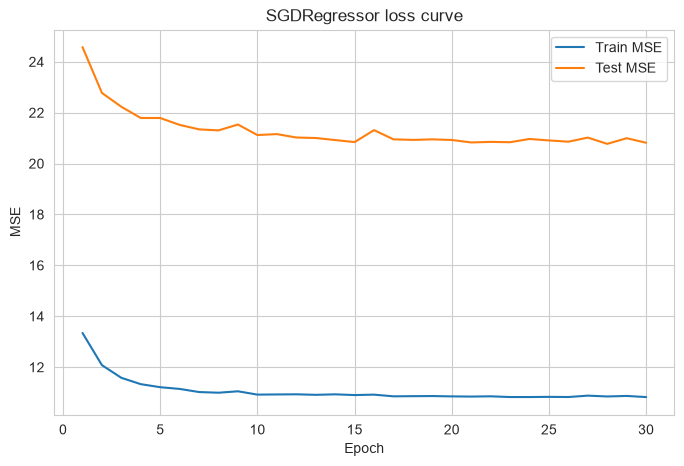

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), sgd_train_losses, label="Train MSE")
plt.plot(range(1, EPOCHS + 1), sgd_test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.show()

**What it shows:**

The training and test MSE decrease as the number of epochs increases, then start to flatten out. The test loss is higher than the training loss, showing that the model performs slightly better on training data than on unseen data.

## 8. Models 2,3 and 4

In [15]:
# Model 2: closed-form linear regression
lin_model = LinearRegression()
lin_model.fit(X_train_s, y_train)

# Model 3: decision tree
tree_model = DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=42)
tree_model.fit(X_train_s, y_train)

#Model 4: random forest
# kept small (50 trees, limited depth) so the saved file is small enough to host
forest_model = RandomForestRegressor(n_estimators=50, max_depth=15, min_samples_leaf=5,
                                     n_jobs=-1, random_state=42)
forest_model.fit(X_train_s, y_train)

print("All models trained")

All models trained


## 9. Comparing the four models (same test set, MSE)

In [16]:
models = {
    "SGDRegressor": sgd_model,
    "LinearRegression": lin_model,
    "DecisionTree": tree_model,
    "RandomForest": forest_model,
}

rows = []
for name, model in models.items():
    train_mse = mean_squared_error(y_train, model.predict(X_train_s))
    test_mse = mean_squared_error(y_test, model.predict(X_test_s))
    rows.append({"Model": name, "Train MSE": train_mse, "Test MSE": test_mse})

comparison = pd.DataFrame(rows).sort_values("Test MSE").reset_index(drop=True)
comparison    

,Model,Train MSE,Test MSE
0,RandomForest,7.543914,18.299262
1,SGDRegressor,10.823552,20.815728
2,DecisionTree,9.906272,21.758433
3,LinearRegression,10.765246,22.776411


In [17]:
best_name = comparison.loc[0, "Model"]
print("Best model (lowest test MSE):", best_name)
print("Test MSE:", round(comparison.loc[0, "Test MSE"], 3))

Best model (lowest test MSE): RandomForest
Test MSE: 18.299


**Best Model:**

RandomForest has the lowest test MSE of **18.299**, making it the best-performing model among the four.

**Why, based on the dataset:**

I chose RandomForest because crop yield can depend on different combinations of factors, such as crop type, country and season. Tree-based models can capture these relationships better than linear models. However, its training MSE (7.544) is lower than its test MSE (18.299) showing that it performs better on training data than on new data.

## 10. MSE vs Huber Loss

**MSE:** Squares every prediction error, meaning large errors have a much bigger effect on the final score.

**Huber Loss:** Handles small errors like MSE but reduces the impact of large errors by treating them linearly.

- If `|error| <= delta`, it uses squared error.

- If `|error| > delta`, it uses linear error.

Since my dataset contains some very large crop yields, I use Huber loss to reduce their impact. I set delta `= 1.0` because most yields are around 1 tonne per hectare.




In [18]:
def huber_loss(y_true, y_pred, delta=1.0):
    error = np.array(y_true) - np.array(y_pred)
    abs_error = np.abs(error)

    small = 0.5 * error ** 2                     # used when error is small
    large = delta * (abs_error - 0.5 * delta)    # used when error is big/large

    return np.mean(np.where(abs_error <= delta, small, large))

#quick check: a small error and a big error
print("Huber for error of 0.5:", huber_loss([1.0], [1.5]))
print("Huber for error of 20:", huber_loss([1.0], [21.0]))
print("MSE for error of 20: ", mean_squared_error([1.0], [21.0]))

Huber for error of 0.5: 0.125
Huber for error of 20: 19.5
MSE for error of 20:  400.0


In [19]:
rows = []
for name, model in models.items():
    train_pred = model.predict(X_train_s)
    test_pred = model.predict(X_test_s)
    rows.append({
        "Model": name,
        "Train MSE": mean_squared_error(y_train,train_pred),
        "Test MSE": mean_squared_error(y_test, test_pred),
        "Train Huber": huber_loss(y_train, train_pred),
        "Test Huber": huber_loss(y_test, test_pred),
    })

loss_comparison = pd.DataFrame(rows).sort_values("Test MSE").reset_index(drop=True)
loss_comparison

,Model,Train MSE,Test MSE,Train Huber,Test Huber
0,RandomForest,7.543914,18.299262,0.978773,1.748917
1,SGDRegressor,10.823552,20.815728,1.280966,2.078935
2,DecisionTree,9.906272,21.758433,1.161544,1.944255
3,LinearRegression,10.765246,22.776411,1.264994,2.087104


**What it shows:**

Huber loss is much lower than MSE because it reduces the impact of large prediction errors instead of squaring them. RandomForest still performs best under both loss functions with the lowest test MSE (18.299) and test Huber loss (1.749). This means my choice of the best model does not change.

### SGDRegressor trained with Huber loss

`SGDRegressor` can also be *trained* with Huber loss (`loss="huber"`). Here we train it with the same learning rate and alpha as before and compare it to the MSE-trained version.

In [20]:
sgd_huber_model, huber_train_curve, huber_test_curve = train_sgd(
    best_lr, best_alpha, EPOCHS, loss="huber", epsilon=1.0)

for name, model in [("SGD trained with MSE", sgd_model), ("SGD trained with Huber", sgd_huber_model)]:
    test_pred = model.predict(X_test_s)
    print(name)
    print("  Test MSE:  ", round(mean_squared_error(y_test, test_pred), 3))
    print("  Test Huber:", round(huber_loss(y_test, test_pred), 3))

SGD trained with MSE
  Test MSE:   20.816
  Test Huber: 2.079
SGD trained with Huber
  Test MSE:   25.232
  Test Huber: 2.081


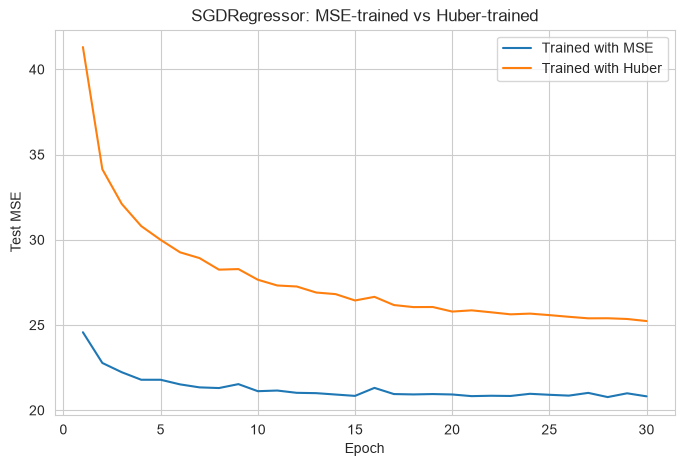

In [21]:
# the curves below record MSE per epoch for both versions
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), sgd_test_losses, label="Trained with MSE")
plt.plot(range(1, EPOCHS + 1), huber_test_curve, label="Trained with Huber")
plt.xlabel("Epoch")
plt.ylabel("Test MSE")
plt.title("SGDRegressor: MSE-trained vs Huber-trained")
plt.legend()
plt.show()

**What it shows:**

The model trained with MSE has a lower test MSE (20.816) compared to the Huber-trained model (25.232). However, both models have almost the same test Huber loss. This shows that using Huber loss did not improve the model's overall performance in this case.

## 11. Which features matter most?

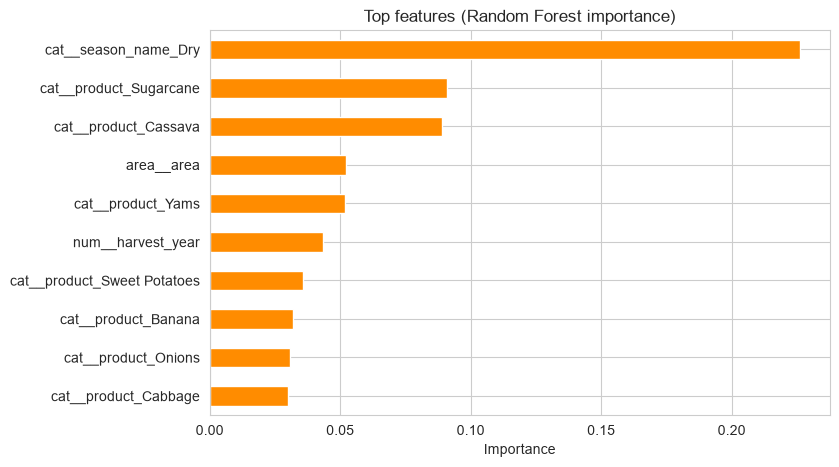

cat__season_name_Dry           0.226248
cat__product_Sugarcane         0.091063
cat__product_Cassava           0.088990
area__area                     0.052123
cat__product_Yams              0.051665
num__harvest_year              0.043332
cat__product_Sweet Potatoes    0.035711
cat__product_Banana            0.031877
cat__product_Onions            0.030647
cat__product_Cabbage           0.029979
dtype: float64

In [22]:
feature_names = preprocessor.get_feature_names_out()
importances = pd.Series(forest_model.feature_importances_, index=feature_names)
top10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
top10.sort_values().plot(kind="barh", color="darkorange")
plt.title("Top features (Random Forest importance)")
plt.xlabel("Importance")
plt.show()

top10

**What it shows:**

The most important feature is `season_name_Dry` followed by `Sugarcane`, `Cassava` and `area`. This shows that the season, crop type and cultivated land area play an important role in predicting crop yield. These factors can help agricultural officers make better farming decisions.

## 12. Scatter plots: Before and after the regression line

I will plot the numeric feature most correlated with `yield`. (The line is a one-feature linear regression used only for this plot.)

In [23]:
# find the numeric feature most correlated with yield (using log of area)
plot_df = train_df[["planting_month", "harvest_month", "harvest_year", "area", "yield"]].copy()
plot_df["log_area"] = np.log1p(plot_df["area"])
plot_df = plot_df.drop(columns="area")

correlations = plot_df.corr()["yield"].drop("yield")
top_feature = correlations.abs().idxmax()
print("Most correlated feature:", top_feature, "->", round(correlations[top_feature], 3))

# use a random sample of points so the plot is readable
sample = plot_df.sample(3000, random_state=42)

Most correlated feature: log_area -> -0.221


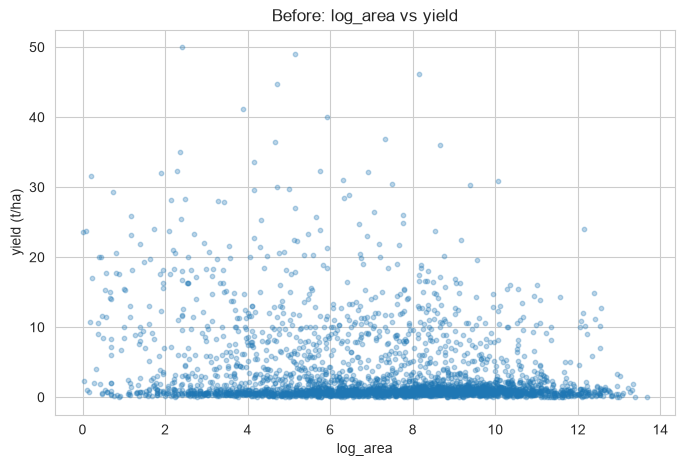

In [24]:
# Scatter Before
plt.figure(figsize=(8, 5))
plt.scatter(sample[top_feature], sample["yield"], alpha=0.3, s=10)
plt.xlabel(top_feature)
plt.ylabel("yield (t/ha)")
plt.title("Before: " + top_feature + " vs yield")
plt.show()

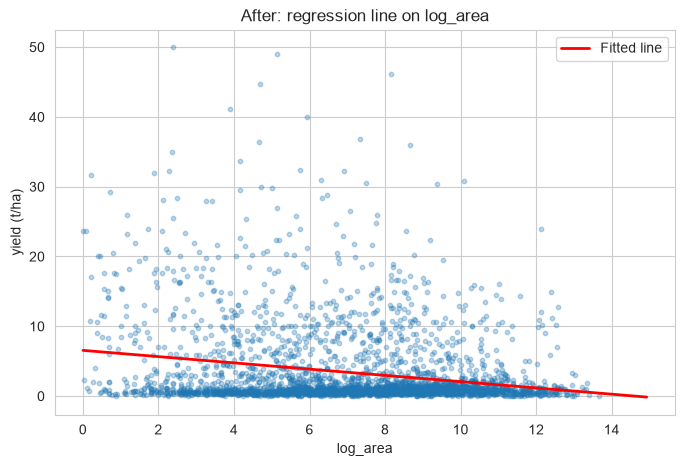

In [25]:
line_model = LinearRegression()
line_model.fit(plot_df[[top_feature]], plot_df["yield"])

x_line = np.linspace(plot_df[top_feature].min(), plot_df[top_feature].max(), 100)
y_line = line_model.predict(pd.DataFrame({top_feature: x_line}))

plt.figure(figsize=(8, 5))
plt.scatter(sample[top_feature], sample["yield"], alpha=0.3, s=10)
plt.plot(x_line, y_line, color="red", linewidth=2, label="Fitted line")
plt.xlabel(top_feature)
plt.ylabel("yield (t/ha)")
plt.title("After: regression line on " + top_feature)
plt.legend()
plt.show()

**What it shows:**

`log_area` has a weak negative correlation with `yield` (-0.221). The points are widely spread around the regression line showing that cultivated area alone does not explain crop yield very well. This means I need other features to make better predictions.

## 13. Saving the best model with its preprocessing

I combined the fitted preprocessor and the best model into one `Pipeline` so the API can pass in raw values and get a prediction.

In [26]:
best_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", models[best_name]),
])

os.makedirs("../API", exist_ok=True)
joblib.dump(best_pipeline, "../API/best_model.pkl", compress=3)

size_mb = os.path.getsize("../API/best_model.pkl") / (1024 * 1024)
print("Saved best_model.pkl, size: {:.1f} MB".format(size_mb))

Saved best_model.pkl, size: 3.1 MB


## 14. Predict one row of the test set

In [27]:
def predict_one_row(row_number):
    # loading the saved pipeline
    loaded_model = joblib.load("../API/best_model.pkl")

    # take one row from the test set
    row = X_test.iloc[[row_number]]

    predicted = loaded_model.predict(row)[0]
    actual = y_test.iloc[row_number]

    print(row.to_string(index=False))
    print("Predicted yield: {:.2f} t/ha".format(predicted))
    print("Actual yield:    {:.2f} t/ha".format(actual))
    return predicted

predict_one_row(0)

country product season_name crop_production_system  planting_month  harvest_month  harvest_year   area
 Angola  Banana        Main               All (PS)              10              4          2016 8706.0
Predicted yield: 21.13 t/ha
Actual yield:    25.50 t/ha


np.float64(21.1304061151042)

## 15. Values the API will accept

I printed the allowed categories and numeric ranges. These are used for the Pydantic validation in the API (Task 2).

In [28]:
for col in cat_cols:
    print(col, "->", sorted(df[col].unique()))
    print()

print(df[["planting_month", "harvest_month", "harvest_year", "area"]].describe().loc[["min", "max"]])

country -> ['Angola', 'Benin', 'Burkina Faso', 'Burundi', 'Cameroon', 'Central African Republic', 'Chad', 'DRC', 'Ethiopia', 'Ghana', 'Kenya', 'Lesotho', 'Liberia', 'Madagascar', 'Malawi', 'Mali', 'Mauritania', 'Mozambique', 'Niger', 'Nigeria', 'Rwanda', 'Senegal', 'Somalia', 'South Africa', 'South Sudan', 'Sudan', 'Tanzania, United Republic of', 'Togo', 'Uganda', 'Zambia', 'Zimbabwe']

product -> ['Avocado', 'Bambara groundnut', 'Banana', 'Barley', 'Bean (Hyacinth)', 'Beans (Rosecoco)', 'Beans (White)', 'Beans (mixed)', 'Beet', 'Bush Bean', 'Cabbage', 'Canola Seed', 'Capsicum Chinense', 'Carrots', 'Cashew (unshelled)', 'Cassava', 'Celery', 'Cereal Crops', 'Chick Peas', 'Chili Pepper', 'Coffee', 'Coriander', 'Cotton', 'Cotton (Acala)', 'Cotton (American)', 'Cottonseed', 'Cowpea', 'Cucumber', 'Eggplant', 'Ethiopian Cabbage', 'Fava Bean', 'Fenugreek', 'Field Peas', 'Fonio', 'Garlic', 'Geocarpa groundnut', 'Ginger', 'Goussi', 'Green Bean', 'Green Peppers', 'Groundnuts (In Shell)', 'Hops',

In [29]:
# Original data used  by/ retrain (the random forest must be refit on old + new rows)
train_df.sample(10000, random_state=42).to_csv("../API/train_data.csv", index=False)
